In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle
import cv2
from scipy import io as io

In [61]:
file_path = project_folder + '/data/movieBinnedSpiking.mat'
# file_path = project_folder + '/data/nat_scenes_data.mat'
all_data = io.loadmat(file_path, squeeze_me=True)

In [43]:
all_data['clean']

array([  1,   2,   3,   4,   5,   6,   8,   9,  10,  11,  13,  14,  15,
        16,  17,  18,  19,  20,  21,  22,  24,  25,  26,  28,  29,  30,
        31,  33,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,
        46,  47,  48,  50,  53,  54,  55,  56,  57,  58,  59,  60,  61,
        62,  65,  66,  67,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  84,  87,  88,  89,  90,  91,  92,  93,
        94,  95,  96,  97,  98,  99, 100, 104, 106, 108, 110, 111, 112,
       114, 115], dtype=uint8)

In [3]:
file_path = project_folder + '/data/binaryCheckerboard.mat'
all_data = io.loadmat(file_path, squeeze_me=True)

In [4]:
# Extract arrays and wrap in Dataset objects
neural = all_data['binaryCheckerboard'].astype(float)  # (93, 120289): cells x frames
stim   = all_data['stimulusFrames']                    # (40, 40, 120289): H x W x frames
samplingFreq = float(all_data['samplingFreq'])

frame_H, frame_W, n_frames = stim.shape

# Reshape stimulus to (H*W, T) to match Dataset convention (N features x P samples)
stim_flat = stim.reshape(-1, n_frames).astype(float)  # (1600, 120289)

D = ds.Dataset(neural)
M = ds.Dataset(stim_flat)

print(f'Neural data shape  (cells x frames): {D.X.shape}')
print(f'Stimulus shape (pixels x frames):    {M.X.shape}')
print(f'Sampling frequency: {samplingFreq} Hz')

Neural data shape  (cells x frames): (93, 120289)
Stimulus shape (pixels x frames):    (1600, 120289)
Sampling frequency: 30.0 Hz


In [5]:
# Determine receptive fields via spike-triggered average
# RF[i, j] = sum_t( response[i,t] * stim[j,t] ) / n_spikes[i]
n_spikes = D.X.sum(axis=1, keepdims=True)  # (N_cells, 1)
RF = (D.X @ M.X.T) / n_spikes              # (N_cells, H*W)

RF_images = RF.reshape(D.N, frame_H, frame_W)
print(f'RF shape: {RF_images.shape}')

RF shape: (93, 40, 40)


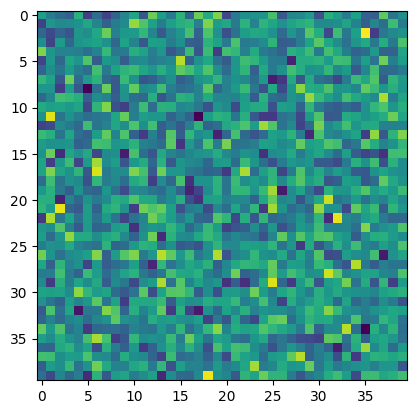

In [32]:
plt.imshow(RF_images[0])

In [67]:
1.5 * 1.2 / 9

0.19999999999999998

In [6]:
# Compute mask by thresholding receptive field
threshold = 0.5  # fraction of each cell's peak |RF| to use as cutoff

masks_flat = np.zeros((D.N, frame_H * frame_W), dtype=bool)
for i in range(D.N):
    rf_power = np.abs(RF[i])
    masks_flat[i] = rf_power > threshold * rf_power.max()

# Union across cells: pixels within any cell's RF
mov_mask = masks_flat.any(axis=0)  # (H*W,)
print(f'Pixels retained: {mov_mask.sum()} / {mov_mask.size} ({100*mov_mask.mean():.1f}%)')

Pixels retained: 1600 / 1600 (100.0%)


In [7]:
# Create new dataset for masked stimulus data
M_masked = ds.Dataset(M.X[mov_mask, :])  # (N_masked_pixels, T)
print(f'Masked stimulus shape: {M_masked.X.shape}')

Masked stimulus shape: (1600, 120289)


In [8]:
# Save masked stimulus dataset
os.makedirs(save_directory, exist_ok=True)
save_path = os.path.join(save_directory, 'M_masked_checkerboard.pkl')
M_masked.save(save_path)
print(f'Saved to {save_path}')

Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_checkerboard.pkl
